# CS156 Session 5 — Maximum Likelihood 1: Naive Bayes

In this session, I explored how Naive Bayes performs classification using Bayes' theorem. The main idea is to estimate how likely each class is given the features of a new observation.

Bayes' theorem is:

$$
P(y \mid x)=\frac{P(x\mid y)P(y)}{P(x)}
$$

For classification, $P(x)$ is the same for every possible class, so I only need to compare:

$$
P(y\mid x)\propto P(y)P(x\mid y)
$$

Naive Bayes simplifies the likelihood by assuming that the features are conditionally independent once the class is known:

$$
P(x_1,\ldots,x_n\mid y)\approx\prod_{i=1}^{n}P(x_i\mid y)
$$

This gives the Naive Bayes classification rule:

$$
\hat{y}=\arg\max_y P(y)\prod_{i=1}^{n}P(x_i\mid y)
$$

The assumption is often not completely true, but it makes the model simple, fast, and useful for high-dimensional problems such as text classification.

# Core Question: SMS Classification

The goal is to classify SMS messages as either `ham` or `spam`.

Naive Bayes cannot directly work with raw text, so the messages first need to be converted into numerical features. Here, I use `TfidfVectorizer`.

TF-IDF gives every token a numerical weight. Term Frequency measures how strongly a word appears in a particular message, while Inverse Document Frequency reduces the weight of words that appear in many messages.

The result is a numerical vector for every SMS. Each position corresponds to one token in the vocabulary; a larger TF-IDF value means that token is more distinctive in that particular message.

In [1]:
# Loading the SMS dataset
import pandas as pd
from sklearn.feature_extraction import text

df = pd.read_csv("https://raw.githubusercontent.com/milindsoorya/Spam-Classifier-in-python/main/dataset/spam.csv", encoding="latin-1")

# Separating class labels and SMS text
labels = df["v1"]
texts = df["v2"]

# Checking the class counts in the loaded dataset
print(labels.value_counts())

# Building TF-IDF features from the messages
vectorizer = text.TfidfVectorizer()
vec_texts = vectorizer.fit_transform(texts)

# Showing the first three original messages
print(texts[:3])

# Showing the non-zero TF-IDF entries for the first three messages
print(vec_texts[:3])
print("TF-IDF matrix shape:", vec_texts.shape)

# Showing a small sample of the learned vocabulary
vocab_sample = list(vectorizer.vocabulary_.items())[:20]
print(vocab_sample)

v1
ham     4825
spam     747
Name: count, dtype: int64
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
Name: v2, dtype: object
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 46 stored elements and shape (3, 8672)>
  Coords	Values
  (0, 3550)	0.1481298737377147
  (0, 8030)	0.22998520738984352
  (0, 4350)	0.3264252905795869
  (0, 5920)	0.2553151503985779
  (0, 2327)	0.25279391746019725
  (0, 1303)	0.24415547176756056
  (0, 5537)	0.15618023117358304
  (0, 4087)	0.10720385321563428
  (0, 1751)	0.2757654045621182
  (0, 3634)	0.1803175103691124
  (0, 8489)	0.22080132794235655
  (0, 4476)	0.2757654045621182
  (0, 1749)	0.3116082237740733
  (0, 2048)	0.2757654045621182
  (0, 7645)	0.15566431601878158
  (0, 3594)	0.15318864840197105
  (0, 1069)	0.3264252905795869
  (0, 8267)	0.18238655630689804
  (1, 5504)	0.27211951321382544
  (1, 4512)	0.4082988561907181
  (1, 43

# Question 2 of 7 — What Is `TfidfVectorizer` Doing?

`TfidfVectorizer` converts text into numbers so that a machine learning model can use it. It first creates a vocabulary from the tokens in the messages. Each token becomes one feature.

The TF part measures how strongly a token appears in a particular message. The IDF part reduces the importance of tokens that appear in many messages, since these words are usually less useful for distinguishing one document from another.

Therefore, each SMS becomes a vector in which every position corresponds to one token and the value represents that token's TF-IDF weight.

For example, an output such as:

`(0, 8267) 0.182`

means that message `0` has a TF-IDF value of about `0.182` for the token stored in feature column `8267`.

The column number is only a feature index; it is not an importance ranking.

In [2]:
# Inspecting a few token-to-column mappings
for token in ["free", "win", "call"]:
    if token in vectorizer.vocabulary_:
        print(token, "-> column", vectorizer.vocabulary_[token])

# Inspecting the first message's TF-IDF representation
print(vec_texts[0])

free -> column 3358
win -> column 8405
call -> column 1813
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 18 stored elements and shape (1, 8672)>
  Coords	Values
  (0, 3550)	0.1481298737377147
  (0, 8030)	0.22998520738984352
  (0, 4350)	0.3264252905795869
  (0, 5920)	0.2553151503985779
  (0, 2327)	0.25279391746019725
  (0, 1303)	0.24415547176756056
  (0, 5537)	0.15618023117358304
  (0, 4087)	0.10720385321563428
  (0, 1751)	0.2757654045621182
  (0, 3634)	0.1803175103691124
  (0, 8489)	0.22080132794235655
  (0, 4476)	0.2757654045621182
  (0, 1749)	0.3116082237740733
  (0, 2048)	0.2757654045621182
  (0, 7645)	0.15566431601878158
  (0, 3594)	0.15318864840197105
  (0, 1069)	0.3264252905795869
  (0, 8267)	0.18238655630689804


# Question 3 of 7 — Based on This Confusion Plot, How Well Does the Model Perform?

I train a Multinomial Naive Bayes classifier using the TF-IDF vectors.

The confusion matrix lets me compare the true labels with the model's predictions. In my run, the model classified all ham messages correctly and correctly identified most spam messages. It missed 132 spam messages by predicting them as ham.

The overall training accuracy is approximately:

$$
\text{Accuracy}
=
\frac{4825+615}{4825+615+132}
\approx 0.976
$$

so the model correctly classifies about 97.6% of these messages.

However, this number should be interpreted carefully. I trained the model and predicted on the same dataset, so this measures training performance rather than generalization to completely unseen SMS messages. I would need a separate test set or cross-validation for a better estimate of real-world performance.

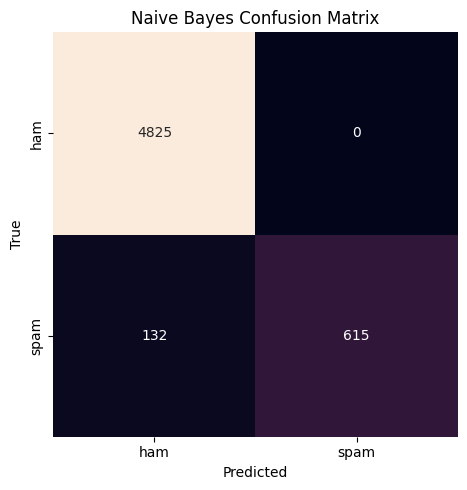

Training accuracy: 0.9763101220387652


In [3]:
# Importing plotting and classification tools
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics, naive_bayes

# Training the Multinomial Naive Bayes model
model = naive_bayes.MultinomialNB()
model.fit(vec_texts, labels)

# Predicting the labels of the same messages
pred_labels = model.predict(vec_texts)

# Calculating the confusion matrix
confusion_mat = metrics.confusion_matrix(labels, pred_labels)

# Plotting the confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_mat, square=True, annot=True, fmt="d", cbar=False, xticklabels=model.classes_, yticklabels=model.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Naive Bayes Confusion Matrix")
plt.tight_layout()
plt.show()

# Calculating training accuracy
accuracy = metrics.accuracy_score(labels, pred_labels)
print("Training accuracy:", accuracy)

# Question 4 of 7 — How Is Naive Bayes Being Learned Here?

The TF-IDF representation contains 8,672 features. Naive Bayes learns a separate class-conditional feature probability for every feature in every class.

There are two classes:

- ham
- spam

Therefore, the model stores:

$$
8672\times2=17,344
$$

feature probability values.

It also learns one class prior for each class:

$$
P(\text{ham})
\qquad\text{and}\qquad
P(\text{spam})
$$

Therefore, the total number of learned numerical values I expect is:

$$
17,344+2=17,346
$$

In simple terms, every token gets one learned value for ham and another for spam; the model also learns how common each class is overall.

Strictly speaking, these are learned stored values rather than 17,346 completely independent degrees of freedom, because the probabilities within each class are normalized.

In [4]:
# Checking the number of classes and features
n_classes = len(model.classes_)
n_features = vec_texts.shape[1]

# Counting the learned feature log-probabilities
feature_values = model.feature_log_prob_.size

# Counting the learned class log-priors
prior_values = model.class_log_prior_.size

# Calculating the total learned numerical values
total_values = feature_values + prior_values

print("Classes:", n_classes)
print("Features:", n_features)
print("Feature probability values:", feature_values)
print("Class prior values:", prior_values)
print("Total learned values:", total_values)

# Checking the model array shapes
print("feature_log_prob_ shape:", model.feature_log_prob_.shape)
print("class_log_prior_ shape:", model.class_log_prior_.shape)

Classes: 2
Features: 8672
Feature probability values: 17344
Class prior values: 2
Total learned values: 17346
feature_log_prob_ shape: (2, 8672)
class_log_prior_ shape: (2,)


# Question 5 of 7 — How Does Naive Bayes Divide the Data Geometrically?

Naive Bayes does not divide the feature space into boxes like a decision tree.

A decision tree repeatedly asks questions such as whether one feature is above or below a threshold. Each split creates smaller regions of the feature space.

Naive Bayes works differently. Each SMS is a point in an 8,672-dimensional TF-IDF space. The model combines the contribution of all features and calculates a score for each class.

Using logarithms, the class score can be written as:

$$
\log P(y)+\sum_i x_i\log P(x_i\mid y)
$$

The predicted class is:

$$
\hat{y}
=
\arg\max_y
\left[
\log P(y)+
\sum_i x_i\log P(x_i\mid y)
\right]
$$

Therefore, there is no actual tree being fitted. Instead, Multinomial Naive Bayes creates one global scoring rule. In this feature representation, comparing the two class log-scores gives a linear decision boundary in the high-dimensional feature space.

In [5]:
# Confirming the dimensionality of the feature space
print("Each SMS has", vec_texts.shape[1], "possible TF-IDF features.")

# Showing the two classes being compared by the model
print("Classes:", model.classes_)

# Showing the shape of the class-specific feature probabilities
print("Feature probability matrix:", model.feature_log_prob_.shape)

Each SMS has 8672 possible TF-IDF features.
Classes: ['ham' 'spam']
Feature probability matrix: (2, 8672)


# Extension Question — Top 30 Tokens With the Highest $P(X\mid\text{spam})$

`MultinomialNB` stores the learned feature probabilities in log form inside `feature_log_prob_`.

I first identify which row represents spam. I then use:

$$
P(X\mid\text{spam})
=
e^{\log P(X\mid\text{spam})}
$$

to convert the log-probabilities back into ordinary probability values.

`vectorizer.vocabulary_` maps each token to its feature column. I reverse this mapping so I can match every learned probability back to the correct token.

Finally, I sort the tokens by their learned spam probability and plot the 30 largest values.

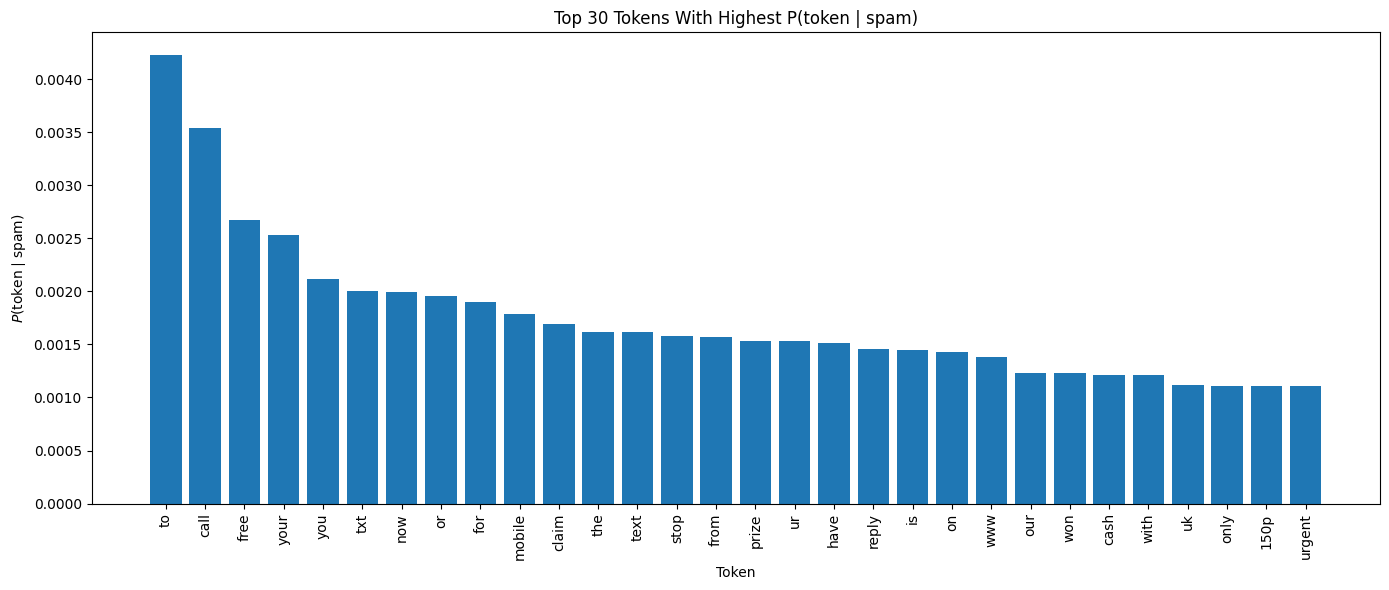

       token  probability
7756      to     0.004229
1813    call     0.003536
3358    free     0.002668
8615    your     0.002529
8609     you     0.002115
7933     txt     0.002002
5420     now     0.001994
5570      or     0.001957
3308     for     0.001896
5089  mobile     0.001786
2054   claim     0.001697
7627     the     0.001621
7595    text     0.001617
7266    stop     0.001577
3397    from     0.001567
6073   prize     0.001535
8051      ur     0.001530
3770    have     0.001516
6399   reply     0.001460
4206      is     0.001445
5525      on     0.001428
8537     www     0.001383
5606     our     0.001235
8464     won     0.001228
1889    cash     0.001211
8433    with     0.001209
7963      uk     0.001116
5537    only     0.001112
351     150p     0.001110
8055  urgent     0.001104


In [6]:
# Importing the required tools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Finding the row corresponding to spam
spam_idx = list(model.classes_).index("spam")

# Converting spam feature log-probabilities back to probabilities
spam_probs = np.exp(model.feature_log_prob_[spam_idx])

# Reversing token -> column into column -> token
index_to_word = {idx: word for word, idx in vectorizer.vocabulary_.items()}

# Matching each token with its learned spam probability
feature_df = pd.DataFrame({
    "token": [index_to_word[i] for i in range(len(spam_probs))],
    "probability": spam_probs})

# Selecting the 30 highest spam probabilities
top30 = feature_df.sort_values("probability", ascending=False).head(30)

# Plotting the highest-probability spam tokens
plt.figure(figsize=(14, 6))
plt.bar(top30["token"], top30["probability"])
plt.xticks(rotation=90)
plt.xlabel("Token")
plt.ylabel(r"$P(\mathrm{token}\mid\mathrm{spam})$")
plt.title("Top 30 Tokens With Highest P(token | spam)")
plt.tight_layout()
plt.show()

print(top30)

# Extension Question — Bottom 30 Tokens With the Lowest $P(X\mid\text{spam})$

I use the same learned spam probabilities, but this time I select the 30 smallest values.

One pattern is immediately visible: many of these tokens have exactly the same probability. In my output, several are rare numerical or mixed alphanumeric tokens such as `000pes`, `24th`, and `1apple`.

Their probabilities are approximately:

$$
P(X\mid\text{spam})\approx0.000084
$$

The equal values make sense because these features are extremely rare or absent from the spam training examples. Multinomial Naive Bayes uses smoothing, so an unseen feature receives a very small non-zero probability rather than exactly zero.

This is important because without smoothing, one unseen feature could make the entire Naive Bayes product equal zero.

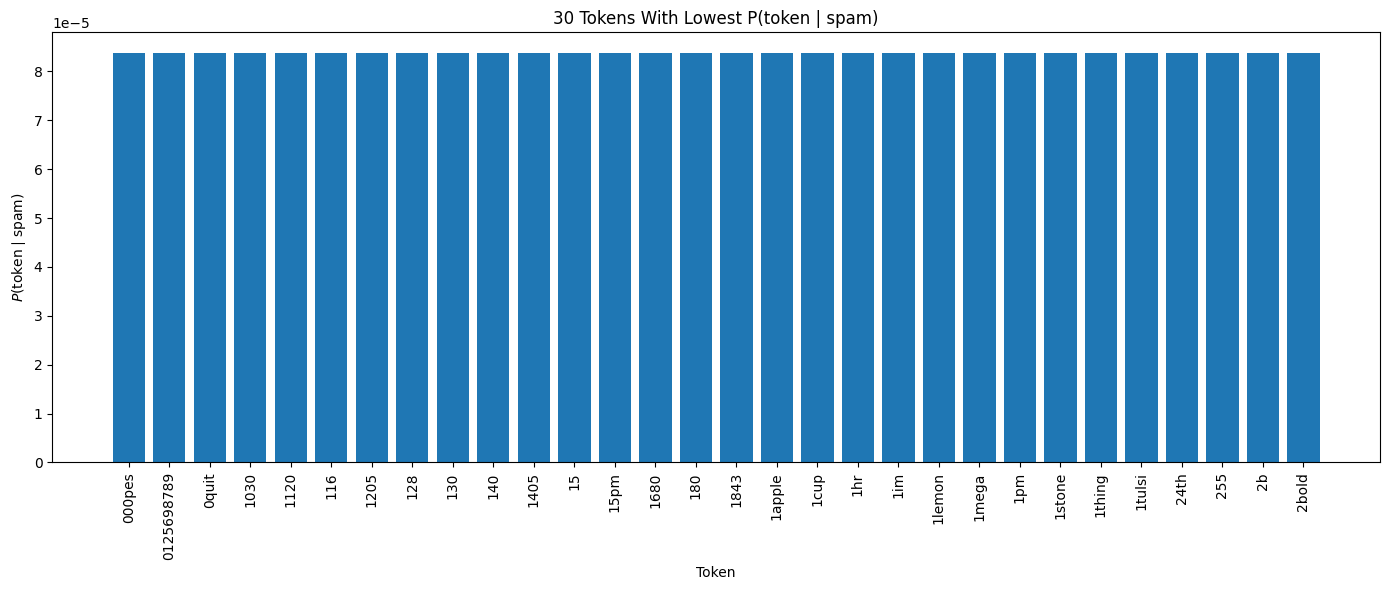

          token  probability
2        000pes     0.000084
8    0125698789     0.000084
296       0quit     0.000084
306        1030     0.000084
313        1120     0.000084
317         116     0.000084
323        1205     0.000084
331         128     0.000084
336         130     0.000084
340         140     0.000084
341        1405     0.000084
348          15     0.000084
362        15pm     0.000084
365        1680     0.000084
369         180     0.000084
370        1843     0.000084
375      1apple     0.000084
377        1cup     0.000084
380         1hr     0.000084
381         1im     0.000084
382      1lemon     0.000084
383       1mega     0.000084
385         1pm     0.000084
389      1stone     0.000084
390      1thing     0.000084
391      1tulsi     0.000084
421        24th     0.000084
425         255     0.000084
437          2b     0.000084
438       2bold     0.000084


In [7]:
# Selecting the 30 lowest spam probabilities
bottom30 = feature_df.nsmallest(30, "probability").sort_values("probability", ascending=False)

# Plotting the lowest-probability spam tokens
plt.figure(figsize=(14, 6))
plt.bar(bottom30["token"], bottom30["probability"])
plt.xticks(rotation=90)
plt.xlabel("Token")
plt.ylabel(r"$P(\mathrm{token}\mid\mathrm{spam})$")
plt.title("30 Tokens With Lowest P(token | spam)")
plt.tight_layout()
plt.show()

# Showing the exact tokens and probabilities
print(bottom30[["token", "probability"]])

# Question 6 of 7 — What Patterns Do You Notice?

The highest $P(X\mid\text{spam})$ tokens include words such as `call`, `free`, `txt`, `mobile`, `prize`, `win`, `cash`, and `urgent`. These words fit the language of spam messages because many spam texts advertise something, promise money or prizes, request a call or text, or create a sense of urgency.

The lowest spam probabilities are different. In my actual output, many are rare numeric or mixed tokens, and several have exactly the same probability. This suggests that they appeared very rarely, or not at all, in the spam examples; smoothing gives them the same small non-zero probability.

However, a high $P(X\mid\text{spam})$ does not automatically mean that a token is a strong spam predictor. What really matters for classification is how the token behaves in both classes.

For example, a token is strong evidence for spam when:

$$
P(X\mid\text{spam})
\gg
P(X\mid\text{ham})
$$

If a token is common in both classes, it may have a high spam probability but still provide little information for separating spam from ham.

In [8]:
# Finding the ham row
ham_idx = list(model.classes_).index("ham")

# Calculating the difference between spam and ham log-probabilities
log_ratio = model.feature_log_prob_[spam_idx] - model.feature_log_prob_[ham_idx]

# Creating a token-level comparison table
comparison_df = pd.DataFrame({
    "token": [index_to_word[i] for i in range(len(log_ratio))],
    "spam_vs_ham_log_ratio": log_ratio})

# Finding the tokens that most strongly favor spam
spam_favoring = comparison_df.sort_values("spam_vs_ham_log_ratio", ascending=False).head(20)

print(spam_favoring)

           token  spam_vs_ham_log_ratio
2054       claim               3.690479
6073       prize               3.590142
351         150p               3.266299
8537         www               3.208316
7785        tone               3.125280
3666  guaranteed               3.086362
7963          uk               3.077836
368           18               3.048050
299         1000               2.947266
608          500               2.923911
2360          cs               2.904368
1320     awarded               2.866720
2109          co               2.788553
363           16               2.778889
6482    ringtone               2.767823
355       150ppm               2.754509
1            000               2.692880
5377       nokia               2.674389
6746     service               2.578023
298          100               2.569991


A positive value means the token is more strongly associated with spam than ham. A large positive value therefore gives more direct evidence that the token pushes the classifier toward spam.

# Deep Dive Question 1 — Creating the Naive Feature Representation

The small dataset contains three types of food:

`pizza`

`pineapple`

`pineapple pizza`

The person likes pizza alone and pineapple alone, but dislikes pineapple pizza.

I first represent the input using two independent binary features:

$$
x_1=\text{pizza present}
$$

$$
x_2=\text{pineapple present}
$$

Therefore:

`pizza` becomes `[1, 0]`

`pineapple` becomes `[0, 1]`

`pineapple pizza` becomes `[1, 1]`

This looks reasonable, but it creates a problem for Naive Bayes because the interaction between the two ingredients is lost.

In [9]:
# Importing the required tools
import numpy as np
from sklearn.naive_bayes import MultinomialNB

# Creating the small food dataset
like = ["pizza"] * 5 + ["pineapple"] * 5
dislike = ["pineapple pizza"] * 5

data = like + dislike
labels_food = [1] * 5 + [1] * 5 + [0] * 5

# Creating separate pizza and pineapple features
def vectorize_naive(x):
    vec = np.zeros(2)

    if "pizza" in x:
        vec[0] = 1

    if "pineapple" in x:
        vec[1] = 1

    return vec

# Vectorizing every food example
data_vec = np.vstack([vectorize_naive(x) for x in data])

print(data_vec)

[[1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [1. 1.]
 [1. 1.]
 [1. 1.]
 [1. 1.]
 [1. 1.]]


# Deep Dive Question 2 — What Is Wrong With This Approach?

The problem comes from the naive conditional-independence assumption.

For the `like` class, Naive Bayes approximates:

$$
P(\text{pizza},\text{pineapple}\mid\text{like})
\approx
P(\text{pizza}\mid\text{like})
P(\text{pineapple}\mid\text{like})
$$

Pizza appears in liked examples and pineapple also appears in liked examples. The model therefore treats `[1,1]` as two pieces of evidence supporting `like`.

But the actual data says something different: pizza is liked alone and pineapple is liked alone, while their combination is always disliked.

The relationship between the features matters. Therefore, the conditional-independence assumption is a poor description of this dataset.

In [10]:
# Training Naive Bayes on the naive feature representation
model_naive = MultinomialNB()
model_naive.fit(data_vec, labels_food)

# Predicting the training examples
pred_naive = model_naive.predict(data_vec)

print("True labels:", labels_food)
print("Predictions:", pred_naive)

True labels: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
Predictions: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


# Deep Dive Question 3 — What Changed With the New Representation?

I do not change the Naive Bayes algorithm itself. Instead, I change how the input is represented.

The new representation creates three separate features:

`pizza` becomes `[1, 0, 0]`

`pineapple` becomes `[0, 1, 0]`

`pineapple pizza` becomes `[0, 0, 1]`

The important change is that `pineapple pizza` is now its own feature rather than being represented as the combination of the two independent features.

This allows the model to learn directly that:

$$
P(\text{pineapple pizza}\mid\text{dislike})
$$

is high.

The example shows that feature engineering can sometimes work around a bad independence assumption. The model is still Naive Bayes; the representation now contains the interaction that mattered.

In [11]:
# Creating a representation with a separate interaction feature
def vectorize_smart(x):
    vec = np.zeros(3)

    if x == "pizza":
        vec[0] = 1
    elif x == "pineapple":
        vec[1] = 1
    else:
        vec[2] = 1

    return vec

# Vectorizing the food examples again
data_vec_smart = np.vstack([vectorize_smart(x) for x in data])

print(data_vec_smart)

# Training Naive Bayes on the improved representation
model_smart = MultinomialNB()
model_smart.fit(data_vec_smart, labels_food)

# Checking whether the interaction is now learned
pred_smart = model_smart.predict(data_vec_smart)

print("True labels:", labels_food)
print("Predictions:", pred_smart)

[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]]
True labels: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
Predictions: [1 1 1 1 1 1 1 1 1 1 0 0 0 0 0]


# Final Session Interpretation

This session helped me understand Naive Bayes as more than just an application of Bayes' theorem.

The model first needs a numerical representation of the input. In the SMS example, TF-IDF converted every message into a high-dimensional vector. Multinomial Naive Bayes then learned class priors and a class-specific probability for every feature.

For prediction, the model combines the prior with the evidence from the features:

$$
P(y\mid x)
\propto
P(y)\prod_iP(x_i\mid y)
$$

In practice, the same computation is performed in log space:

$$
\log P(y\mid x)
\propto
\log P(y)+\sum_i\log P(x_i\mid y)
$$

The model is called naive because it assumes the features are conditionally independent given the class. The SMS example shows why this can work surprisingly well with many text features, while the pineapple-pizza example shows where the assumption can fail.

The biggest lesson for me is that the representation matters as much as the classifier. A model can fail because the features hide an important interaction; changing the representation can sometimes make the same model work much better.